In [8]:
!pip install vaderSentiment
!pip install transformers
!pip install torch
!pip install pandas
!pip install matplotlib
!pip install sentencepiece
!pip install emoji

   ---------------------------------------- 0.0/1.1 MB ? eta -:--:--
   ---------------------------------------- 1.1/1.1 MB 8.4 MB/s eta 0:00:00


In [9]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch

In [10]:
analyzer_vader = SentimentIntensityAnalyzer()

In [11]:
model_name = "cardiffnlp/twitter-roberta-base-sentiment-latest"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

analyzer_roberta = pipeline(
    "sentiment-analysis",
    model=model,
    tokenizer=tokenizer
)

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

C:\Users\kingd\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kingd\.cache\huggingface\hub\models--cardiffnlp--twitter-roberta-base-sentiment-latest. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cpu


In [12]:
texts = [
    "I love living in this neighbourhood!",
    "The noise every night makes me so angry.",
    "Everything feels okay and calm today.",
    "I am disappointed with the cleanliness of the area.",
    "My neighbours are very supportive and friendly.",
    "I feel stressed about community problems.",
]

In [18]:
vader_results = []

for text in texts:
    score = analyzer_vader.polarity_scores(text)
    sentiment = (
        "positive" if score["compound"] >= 0.05 else
        "negative" if score["compound"] <= -0.05 else
        "neutral"
    )
    vader_results.append([text, sentiment, score["compound"]])

df_vader = pd.DataFrame(vader_results, columns=["Feedback", "VADER Sentiment", "VADER Score"])
df_vader


,Feedback,VADER Sentiment,VADER Score
0,I love living in this neighbourhood!,positive,0.6696
1,The noise every night makes me so angry.,negative,-0.6418
2,Everything feels okay and calm today.,positive,0.4939
3,I am disappointed with the cleanliness of the ...,negative,-0.4767
4,My neighbours are very supportive and friendly.,positive,0.7146
5,I feel stressed about community problems.,negative,-0.6249


In [20]:
roberta_results = []

for text in texts:
    res = analyzer_roberta(text)[0]
    roberta_results.append([text, res["label"], res["score"]])

df_roberta = pd.DataFrame(roberta_results, columns=["Feedback", "RoBERTa Sentiment", "Confidence"])
df_roberta


,Feedback,RoBERTa Sentiment,Confidence
0,I love living in this neighbourhood!,positive,0.983502
1,The noise every night makes me so angry.,negative,0.948255
2,Everything feels okay and calm today.,positive,0.927524
3,I am disappointed with the cleanliness of the ...,negative,0.925158
4,My neighbours are very supportive and friendly.,positive,0.970290
5,I feel stressed about community problems.,negative,0.830052


In [22]:
df_compare = pd.concat([df_vader, df_roberta.drop(columns=["Feedback"])], axis=1)
df_compare

,Feedback,VADER Sentiment,VADER Score,RoBERTa Sentiment,Confidence
0,I love living in this neighbourhood!,positive,0.6696,positive,0.983502
1,The noise every night makes me so angry.,negative,-0.6418,negative,0.948255
2,Everything feels okay and calm today.,positive,0.4939,positive,0.927524
3,I am disappointed with the cleanliness of the ...,negative,-0.4767,negative,0.925158
4,My neighbours are very supportive and friendly.,positive,0.7146,positive,0.970290
5,I feel stressed about community problems.,negative,-0.6249,negative,0.830052


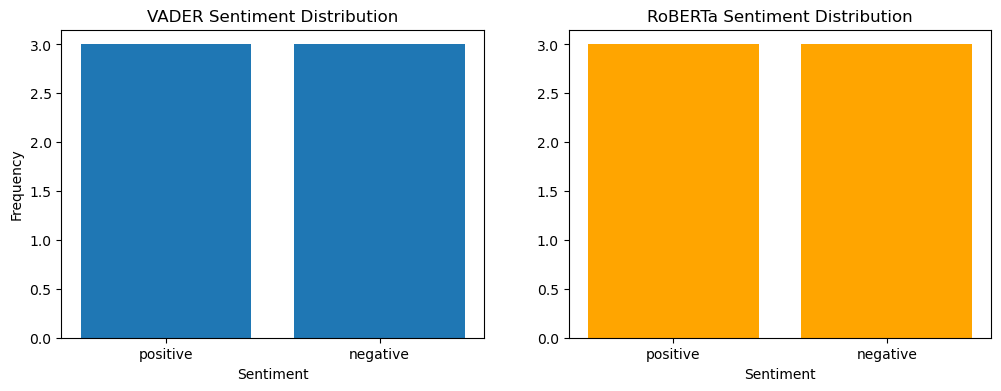

In [24]:
vader_counts = df_vader["VADER Sentiment"].value_counts()
roberta_counts = df_roberta["RoBERTa Sentiment"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(vader_counts.index, vader_counts.values)
axes[0].set_title("VADER Sentiment Distribution")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Frequency")

axes[1].bar(roberta_counts.index, roberta_counts.values, color='orange')
axes[1].set_title("RoBERTa Sentiment Distribution")
axes[1].set_xlabel("Sentiment")

plt.show()

In [26]:
df_compare.to_csv("vader_roberta_results.csv", index=False)